<a href="https://colab.research.google.com/github/thvsbg/PyTorch/blob/main/Wine_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd


In [95]:
from sklearn.datasets import load_wine
data=load_wine()
features=data.data
val=data.target
print(features[:5])
print(val[:5])

[[1.423e+01 1.710e+00 2.430e+00 1.560e+01 1.270e+02 2.800e+00 3.060e+00
  2.800e-01 2.290e+00 5.640e+00 1.040e+00 3.920e+00 1.065e+03]
 [1.320e+01 1.780e+00 2.140e+00 1.120e+01 1.000e+02 2.650e+00 2.760e+00
  2.600e-01 1.280e+00 4.380e+00 1.050e+00 3.400e+00 1.050e+03]
 [1.316e+01 2.360e+00 2.670e+00 1.860e+01 1.010e+02 2.800e+00 3.240e+00
  3.000e-01 2.810e+00 5.680e+00 1.030e+00 3.170e+00 1.185e+03]
 [1.437e+01 1.950e+00 2.500e+00 1.680e+01 1.130e+02 3.850e+00 3.490e+00
  2.400e-01 2.180e+00 7.800e+00 8.600e-01 3.450e+00 1.480e+03]
 [1.324e+01 2.590e+00 2.870e+00 2.100e+01 1.180e+02 2.800e+00 2.690e+00
  3.900e-01 1.820e+00 4.320e+00 1.040e+00 2.930e+00 7.350e+02]]
[0 0 0 0 0]


In [ ]:
##finding the number of features for each wine
print(len(features[0]))

13


In [ ]:
import collections
val_unique_counts=collections.Counter(val)
print(val_unique_counts)

Counter({np.int64(1): 71, np.int64(0): 59, np.int64(2): 48})


In [ ]:
##finding the range of each feature
min_max=pd.DataFrame(columns=["min","max"])
for col in range(len(features[0])):
  min_max[f'{data.features[col]}']


In [ ]:
cols=data.feature_names
print(cols)


['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'v', 'a', 'l']


In [ ]:
wine_1=[1 if val[i]==0 else 0 for i in range(len(val))]
wine_2=[1 if val[i]==1 else 0 for i in range(len(val))]
wine_3=[1 if val[i]==2 else 0 for i in range(len(val))]
print(wine_1[:5])
print(wine_2[:5])
print(wine_3[:5])

[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0]
[0, 0, 0, 0, 0]


In [ ]:
df=pd.DataFrame(features,columns=data.feature_names)
df["wine_1"]=wine_1
df["wine_2"]=wine_2
df["wine_3"]=wine_3
print(df[:5])

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  wine_1  wine_2  wine

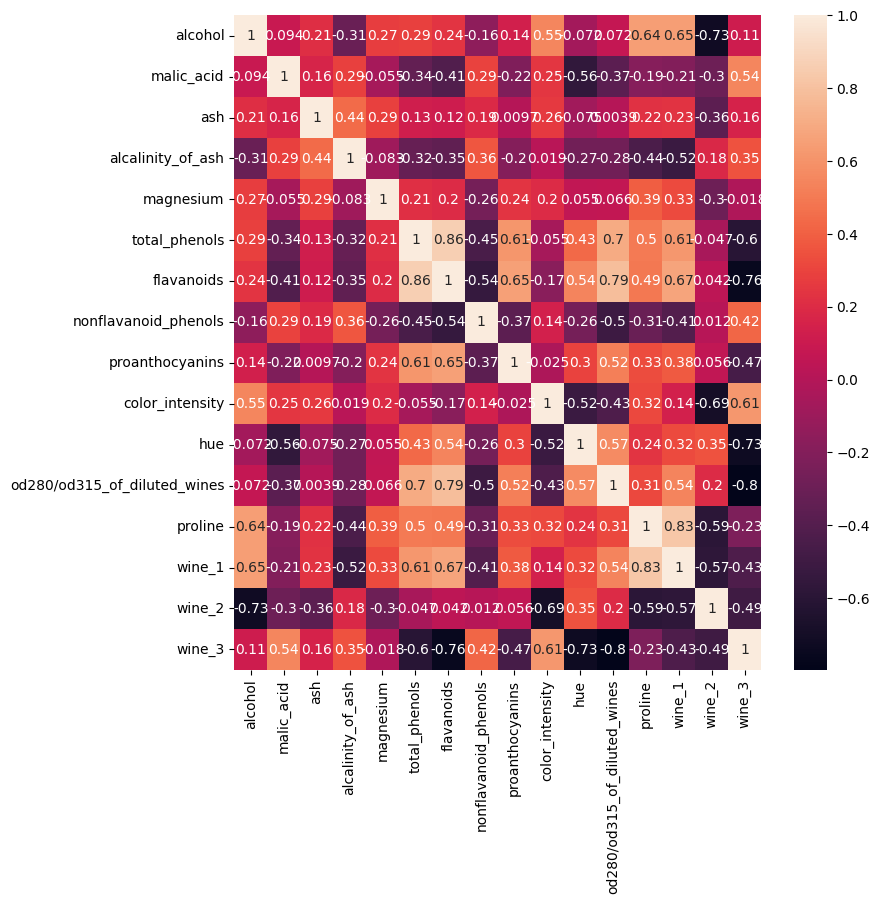

In [ ]:
##visuzlization of corelation between different features to the classified value using heatmap
import seaborn as sns
fig=plt.figure(figsize=(8.5,8.5))
correlation=df.corr(numeric_only=True)
sns.heatmap(correlation,annot=True)
plt.show()


1. Wine_1 is strongly correlated to total_phenols and flavanoids.Let's further analyze using a scatter plot


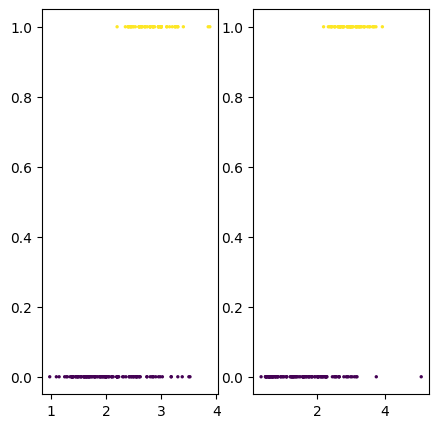

In [ ]:
##exploring relation between wine_1 and total_phenols, flavanoids
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(5,5))
ax1.scatter(df["total_phenols"],df["wine_1"],c=df["wine_1"],s=2)

ax2.scatter(df["flavanoids"],df["wine_1"],c=df["wine_1"],s=2)

plt.show()

##Building a nn

In [ ]:
from torch import nn


In [96]:
##dataprep
features=torch.from_numpy(features).type(torch.float)
val=torch.from_numpy(val).type(torch.LongTensor)
print(features[:5])
print(val[:5])

tensor([[1.4230e+01, 1.7100e+00, 2.4300e+00, 1.5600e+01, 1.2700e+02, 2.8000e+00,
         3.0600e+00, 2.8000e-01, 2.2900e+00, 5.6400e+00, 1.0400e+00, 3.9200e+00,
         1.0650e+03],
        [1.3200e+01, 1.7800e+00, 2.1400e+00, 1.1200e+01, 1.0000e+02, 2.6500e+00,
         2.7600e+00, 2.6000e-01, 1.2800e+00, 4.3800e+00, 1.0500e+00, 3.4000e+00,
         1.0500e+03],
        [1.3160e+01, 2.3600e+00, 2.6700e+00, 1.8600e+01, 1.0100e+02, 2.8000e+00,
         3.2400e+00, 3.0000e-01, 2.8100e+00, 5.6800e+00, 1.0300e+00, 3.1700e+00,
         1.1850e+03],
        [1.4370e+01, 1.9500e+00, 2.5000e+00, 1.6800e+01, 1.1300e+02, 3.8500e+00,
         3.4900e+00, 2.4000e-01, 2.1800e+00, 7.8000e+00, 8.6000e-01, 3.4500e+00,
         1.4800e+03],
        [1.3240e+01, 2.5900e+00, 2.8700e+00, 2.1000e+01, 1.1800e+02, 2.8000e+00,
         2.6900e+00, 3.9000e-01, 1.8200e+00, 4.3200e+00, 1.0400e+00, 2.9300e+00,
         7.3500e+02]])
tensor([0, 0, 0, 0, 0])


In [97]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(features,val,test_size=0.2, random_state=42)

In [98]:
print(X_train.dtype)

torch.float32


In [106]:
class WineClassification(nn.Module):
  def __init__(self,input_features,hidden_units,output_features):
    super().__init__()
    self.nn_stack=nn.Sequential(
        nn.Linear(input_features,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,output_features)
    )

  def forward(self,x):
    return self.nn_stack(x)




In [131]:
model_0=WineClassification(13,5,3)
loss_fn=nn.CrossEntropyLoss()
opt=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [136]:
##train loop
RANDOM_SEED=42
torch.random.manual_seed(RANDOM_SEED)
epochs=1000
train_loss=[]
for epoch in range(epochs):
  model_0.train()
  pred_logits=model_0(X_train).squeeze()
  pred_prob=torch.softmax(pred_logits,dim=1)
  pred_labels=torch.argmax(pred_prob,dim=1)

  loss=loss_fn(pred_logits,y_train)
  train_loss.append(loss.detach())


  opt.zero_grad

  loss.backward()

  opt.step()

  model_0.eval()
  with torch.inference_mode():
    test_pred_logits=model_0(X_test)
    test_pred_prob=torch.softmax(test_pred_logits,dim=1)
    test_pred_labels=torch.argmax(test_pred_prob,dim=1)

    test_loss=loss_fn(test_pred_logits,y_test)

  if epoch%1000==0:
    print(f'loss at epoch no.{epoch} is: {loss}')

loss at epoch no.0 is: 1.1063836812973022


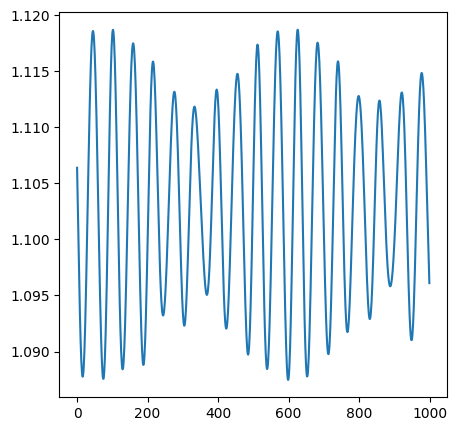

In [137]:
fig=plt.figure(figsize=(5,5))
plt.plot(train_loss)
plt.show()